# Company A – Churn PoC: "Renew & Upgrade" retention programme
GCI World 2026 – Final Assignment notebook (reproducible analysis behind the slides).

**Business question.** Which customers are about to leave in the next 31–60 days, why, and is a targeted
handset-upgrade / renewal offer worth more than it costs?

Structure: 1. Setup & data · 2. EDA · 3. Problem definition · 4. Feature engineering ·
5. Experiments (3 models, 5-fold CV + hold-out) · 6. Explainability (SHAP) · 7. Business impact simulation.

All figures used in the slides are written to `figures/`.

In [1]:
import os, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))  # silence joblib core-count probe on Windows
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
import shap
try:  # Windows without `wmic`: joblib's physical-core probe prints a harmless traceback; use logical cores instead
    import joblib.externals.loky.backend.context as _lctx
    _lctx._count_physical_cores = lambda: (os.cpu_count(), None)
except Exception:
    pass

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# Slide palette
NAVY, ORANGE, GREY, LIGHT, TEAL = "#1F3A5F", "#E07A1F", "#8A94A6", "#DCE3EC", "#2A9D8F"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#444",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# Locate the dataset (works from repo root, analysis/ folder, or Colab folder containing telecom/)
candidates = [Path("telecom"), Path("../Final Assignment/Final Assignment/telecom"),
              Path("Final Assignment/Final Assignment/telecom")]
DATA = next(p for p in candidates if (p / "Client.csv").exists())
print("Data folder:", DATA.resolve())

C:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data folder: C:\Users\ASUS\Downloads\GCI 2026\Final Assignment\Final Assignment\telecom


## 1. Load & merge
`Client.csv` (account/household/handset) and `Record.csv` (usage, billing, network quality, target) are
1:1 on `Customer_ID`.

In [2]:
client = pd.read_csv(DATA / "Client.csv")
record = pd.read_csv(DATA / "Record.csv")
df = record.merge(client, on="Customer_ID", how="inner")
print("Client", client.shape, "| Record", record.shape, "| Merged", df.shape)
print("Duplicate IDs:", df.Customer_ID.duplicated().sum())
df.head(3)

Client (100000, 50) | Record (100000, 51) | Merged (100000, 100)
Duplicate IDs: 0


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,A,0.0,N,U,Y,U,U,U,Y,1504.0


## 2. EDA
### 2.1 Data quality: types, missingness, implausible values

In [3]:
miss = df.isna().mean().sort_values(ascending=False)
print(miss[miss > 0].round(3).head(15))
obj_cols = df.select_dtypes("object").columns.tolist()
print("\nText columns:", obj_cols)
print("\nImplausible values:")
for c in ["rev_Mean", "totmrc_Mean", "eqpdays", "mou_Mean"]:
    print(f"  {c}: {(df[c] < 0).sum()} negative rows")

numbcars            0.494
dwllsize            0.383
HHstatin            0.379
ownrent             0.337
dwlltype            0.319
lor                 0.302
income              0.254
adults              0.230
infobase            0.221
hnd_webcap          0.102
prizm_social_one    0.074
avg6mou             0.028
avg6qty             0.028
avg6rev             0.028
truck               0.017
dtype: float64

Text columns: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']

Implausible values:
  rev_Mean: 5 negative rows
  totmrc_Mean: 23 negative rows
  eqpdays: 133 negative rows
  mou_Mean: 0 negative rows


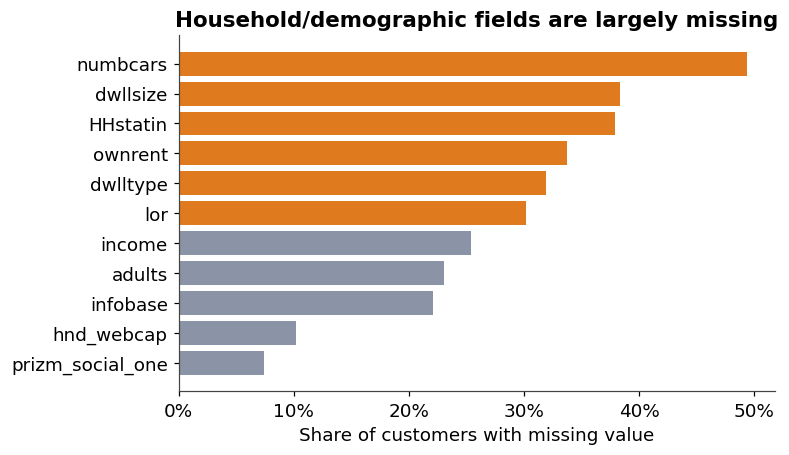

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
top = miss[miss > 0.05]
ax.barh(top.index[::-1], top.values[::-1] * 100, color=[ORANGE if v > 0.3 else GREY for v in top.values[::-1]])
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Household/demographic fields are largely missing")
ax.set_xlabel("Share of customers with missing value")
plt.savefig(FIG / "missing.png"); plt.show()

### 2.2 Target balance
Churn = churned 31–60 days after the observation date.

In [5]:
rate = df.churn.mean()
print(df.churn.value_counts(), f"\nChurn rate: {rate:.1%}")
# NOTE: ~50% is far above real US postpaid churn (~0.8-1% per month, T-Mobile 10-K 2024) ->
# the PoC sample is balanced/oversampled. Ranking quality (ROC-AUC, lift) transfers; absolute counts must be rescaled.

churn
0    50438
1    49562
Name: count, dtype: int64 
Churn rate: 49.6%


### 2.3 Where is churn concentrated? (candidate drivers)

In [6]:
def churn_by(series, bins=None, labels=None):
    s = pd.cut(series, bins, labels=labels) if bins is not None else series
    return df.groupby(s, observed=True).churn.agg(rate="mean", n="size")

tenure = churn_by(df.months, [0, 9, 10, 12, 15, 24, 61], ["≤9", "10", "11–12", "13–15", "16–24", "25+"])
eqp = churn_by(df.eqpdays.clip(lower=0), [-1, 180, 365, 545, 730, 2000], ["<6m", "6–12m", "12–18m", "18–24m", "24m+"])
print(tenure, eqp, sep="\n\n")

            rate      n
months                 
≤9      0.318311  14068
10      0.402736   4313
11–12   0.637249  14062
13–15   0.538182  14038
16–24   0.507874  28830
25+     0.493702  24689

             rate      n
eqpdays                 
<6m      0.417362  18327
6–12m    0.469716  36356
12–18m   0.536933  21539
18–24m   0.540799  12966
24m+     0.578947  10811


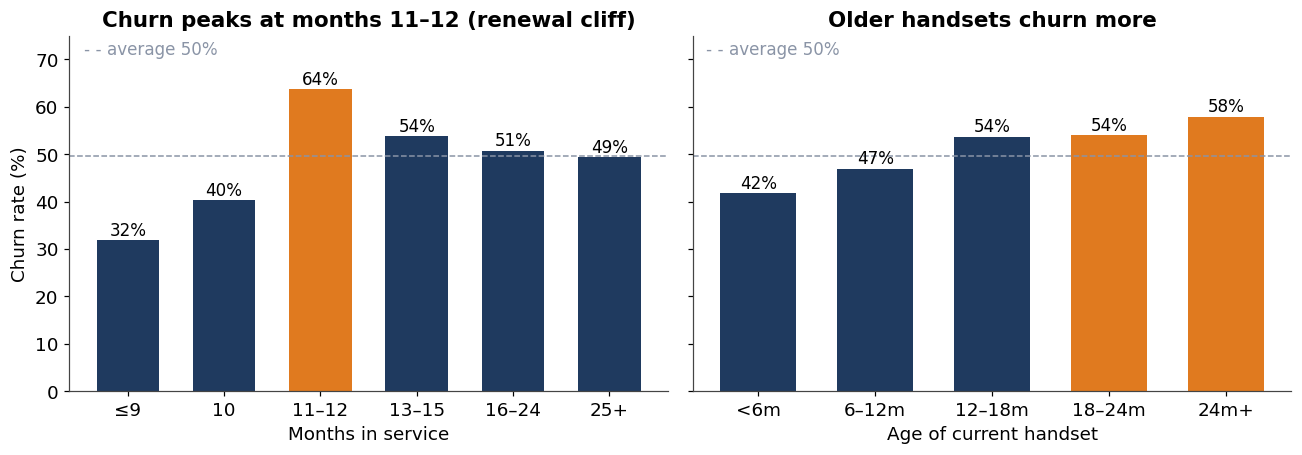

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, tab, title, xlabel, hi in [
    (axes[0], tenure, "Churn peaks at months 11–12 (renewal cliff)", "Months in service", ["11–12"]),
    (axes[1], eqp, "Older handsets churn more", "Age of current handset", ["18–24m", "24m+"]),
]:
    cols = [ORANGE if str(i) in hi else NAVY for i in tab.index]
    bars = ax.bar(tab.index.astype(str), tab.rate * 100, color=cols, width=0.65)
    ax.axhline(rate * 100, ls="--", color=GREY, lw=1); ax.text(-0.45, 71, f"- - average {rate:.0%}", color=GREY, ha="left", fontsize=11)
    for b, v in zip(bars, tab.rate):
        ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=11)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylim(0, 75)
axes[0].set_ylabel("Churn rate (%)")
plt.tight_layout(); plt.savefig(FIG / "eda_tenure_handset.png"); plt.show()

                      rate      n
hnd_webcap                       
Web + multimedia  0.470799  75733
Web only          0.563028  13843
Unknown           0.586435  10424

               rate      n
hnd_price                 
≤$30       0.574615  26094
$30–80     0.508935  18914
$80–130    0.464321  21147
$130–150   0.468119  22035
>$150      0.410198  10963

                 rate      n
refurb_new                  
New          0.489105  85593
Refurbished  0.534361  14406


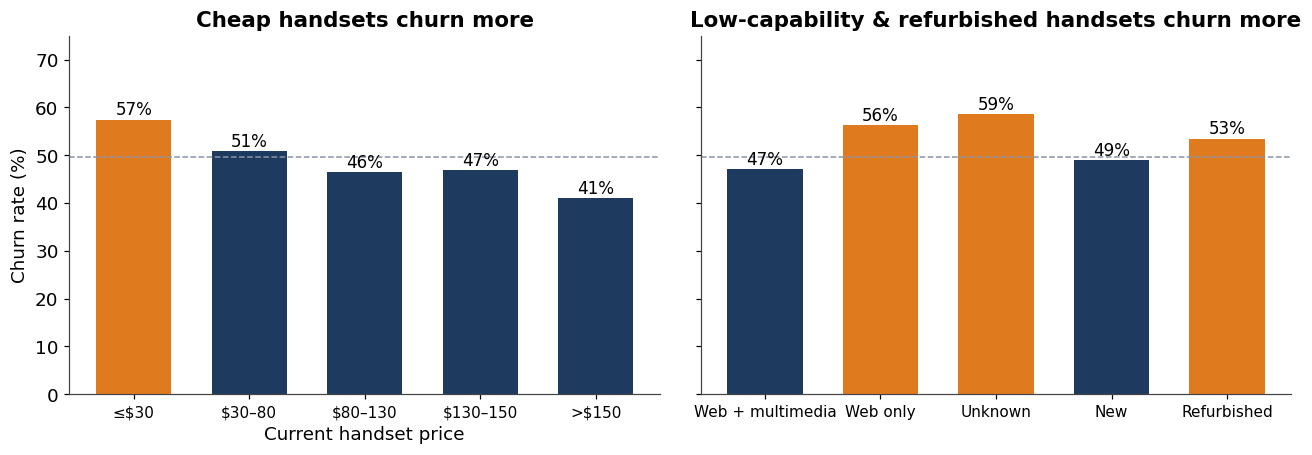

In [8]:
# Handset capability & price
web = df.hnd_webcap.fillna("Unknown").replace({"WCMB": "Web + multimedia", "WC": "Web only", "UNKW": "Unknown"})
web_t = df.groupby(web).churn.agg(rate="mean", n="size").loc[["Web + multimedia", "Web only", "Unknown"]]
price = churn_by(df.hnd_price, [0, 30, 80, 130, 150, 500], ["≤$30", "$30–80", "$80–130", "$130–150", ">$150"])
ref = df.groupby(df.refurb_new.map({"N": "New", "R": "Refurbished"})).churn.agg(rate="mean", n="size")
print(web_t, price, ref, sep="\n\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, tab, title, xlabel in [
    (axes[0], price, "Cheap handsets churn more", "Current handset price"),
    (axes[1], pd.concat([web_t, ref]), "Low-capability & refurbished handsets churn more", ""),
]:
    cols = [ORANGE if v > rate + 0.02 else NAVY for v in tab.rate]
    bars = ax.bar(tab.index.astype(str), tab.rate * 100, color=cols, width=0.65)
    ax.axhline(rate * 100, ls="--", color=GREY, lw=1)
    for b, v in zip(bars, tab.rate):
        ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=11)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylim(0, 75); ax.tick_params(axis="x", labelsize=10)
axes[0].set_ylabel("Churn rate (%)")
plt.tight_layout(); plt.savefig(FIG / "eda_handset_quality.png"); plt.show()

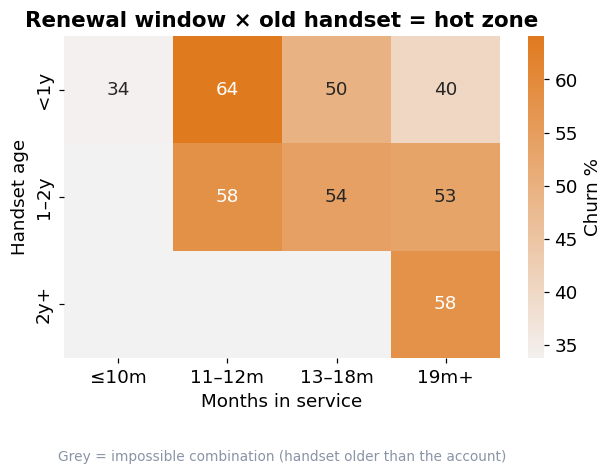

tenure    ≤10m  11–12m  13–18m   19m+
handset                              
<1y      0.338   0.641   0.497  0.403
1–2y       NaN   0.581   0.542  0.533
2y+        NaN     NaN     NaN  0.579


In [9]:
# Interaction: renewal window x handset age -> the "hot zone"
hm = df.assign(
    tenure=pd.cut(df.months, [0, 10, 12, 18, 61], labels=["≤10m", "11–12m", "13–18m", "19m+"]),
    handset=pd.cut(df.eqpdays.clip(lower=0), [-1, 365, 730, 2000], labels=["<1y", "1–2y", "2y+"]),
).pivot_table(index="handset", columns="tenure", values="churn", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.set_facecolor("#F2F2F2")
sns.heatmap(hm * 100, annot=True, fmt=".0f", cmap=sns.light_palette(ORANGE, as_cmap=True), cbar_kws={"label": "Churn %"}, ax=ax)
ax.set_title("Renewal window × old handset = hot zone"); ax.set_xlabel("Months in service"); ax.set_ylabel("Handset age")
ax.text(0.5, -0.32, "Grey = impossible combination (handset older than the account)", transform=ax.transAxes, ha="center", fontsize=9, color=GREY)
plt.savefig(FIG / "eda_heatmap.png"); plt.show()
print(hm.round(3))

In [10]:
# Other candidates checked: usage change, customer care, revenue, credit class, area
for name, s in {
    "change_mou decile": pd.qcut(df.change_mou, 5),
    "custcare_Mean": pd.cut(df.custcare_Mean, [-1, 0, 3, 1000]),
    "rev_Mean quintile": pd.qcut(df.rev_Mean, 5),
    "asl_flag": df.asl_flag,
}.items():
    print(name, df.groupby(s, observed=True).churn.mean().round(3).to_dict())
area = df.groupby("area").churn.mean().sort_values()
print("Area range:", area.round(3).iloc[[0, -1]].to_dict())

change_mou decile {Interval(-3875.001, -119.5, closed='right'): 0.54, Interval(-119.5, -28.75, closed='right'): 0.494, Interval(-28.75, 8.75, closed='right'): 0.509, Interval(8.75, 94.25, closed='right'): 0.456, Interval(94.25, 31219.25, closed='right'): 0.467}
custcare_Mean {Interval(-1, 0, closed='right'): 0.518, Interval(0, 3, closed='right'): 0.48, Interval(3, 1000, closed='right'): 0.447}
rev_Mean quintile {Interval(-6.1690000000000005, 30.852, closed='right'): 0.529, Interval(30.852, 40.04, closed='right'): 0.49, Interval(40.04, 54.095, closed='right'): 0.485, Interval(54.095, 78.831, closed='right'): 0.486, Interval(78.831, 3843.262, closed='right'): 0.485}
asl_flag {'N': 0.51, 'Y': 0.409}
Area range: {'MIDWEST AREA': 0.459, 'NORTHWEST/ROCKY MOUNTAIN AREA': 0.569}


**EDA take-aways (early hypotheses / pain points)**
1. A **renewal cliff**: churn jumps from 32% (≤9 months) to 64% at months 11–12 – customers leave as their first-year commitment ends.
2. **Ageing, low-end handsets**: churn rises from 42% (<6m) to 58% (2y+); cheap (≤$30), refurbished and non-web phones are all above average.
3. Combined, *renewal window × old handset* is the hot zone (heatmap).
4. Revenue level and customer-care calls are weak separators on their own → churn is multi-factor, motivating an ML model.
5. Household fields are 20–50% missing → treat "missing" as information, not noise.

## 3. Problem definition
* **Business objective:** reduce churn (and revenue loss) at the lowest retention cost.
* **Decision supported:** each month, *whom* to contact with a renewal/upgrade offer and *which* offer.
* **Target:** `churn` (1 = left 31–60 days after observation). Unit: one customer.
* **ML task:** binary classification → a churn-risk score used to rank customers.
* **Metric:** ROC-AUC (ranking quality, threshold-free) + precision/recall in the top-20% targeted group
  (what the campaign actually touches). Accuracy reported for completeness (classes are balanced).

## 4. Feature engineering

In [11]:
# `ethnic` is excluded on purpose: a protected attribute must not decide who receives offers (fairness / regulation).
X = df.drop(columns=["churn", "Customer_ID", "ethnic"]).copy()
obj_cols = [c for c in obj_cols if c != "ethnic"]
y = df.churn.values

# Clean implausible values
for c in ["rev_Mean", "totmrc_Mean", "eqpdays"]:
    X.loc[X[c] < 0, c] = np.nan

eps = 1e-6
X["handset_age_vs_tenure"] = X.eqpdays / (X.months * 30.4)          # 1 = original phone, never upgraded
X["in_renewal_window"] = X.months.between(11, 12).astype(int)        # EDA renewal cliff
X["usage_trend_3m"] = X.avg3mou / (X.avgmou + eps)                   # recent vs lifetime usage
X["rev_trend_3m"] = X.avg3rev / (X.avgrev + eps)
X["drop_block_rate"] = X.drop_blk_Mean / (X.attempt_Mean + eps)      # network quality experienced
X["overage_share"] = X.ovrrev_Mean / (X.rev_Mean.abs() + eps)        # bill shock
X["care_per_100_calls"] = 100 * X.custcare_Mean / (X.attempt_Mean + eps)
X["rev_per_minute"] = X.rev_Mean / (X.mou_Mean + 1)

for c in obj_cols:
    X[c] = X[c].fillna("Missing").astype("category")   # keep missing as its own category
num_cols = [c for c in X.columns if c not in obj_cols]
print("Features:", X.shape[1], "| numeric:", len(num_cols), "| categorical:", len(obj_cols))

Features: 105 | numeric: 85 | categorical: 20


In [12]:
# Leakage check: no single numeric feature should be "too good to be true"
single_auc = {c: roc_auc_score(y, X[c].fillna(X[c].median())) for c in num_cols}
single_auc = pd.Series({k: max(v, 1 - v) for k, v in single_auc.items()}).sort_values(ascending=False)
print("Top single-feature AUCs (no leakage if all well below ~0.9):\n", single_auc.head(8).round(3))

Top single-feature AUCs (no leakage if all well below ~0.9):
 eqpdays                  0.574
hnd_price                0.558
rev_per_minute           0.548
usage_trend_3m           0.546
totmrc_Mean              0.542
mou_opkv_Mean            0.541
handset_age_vs_tenure    0.541
mou_cvce_Mean            0.541
dtype: float64


## 5. Experiments
Hold-out 20% test set (never touched during model selection) + 5-fold stratified CV on the training part.
* **Logistic Regression** – interpretable linear baseline (one-hot + standardised; needs scaling).
* **Random Forest** – non-linear bagging baseline.
* **LightGBM** – gradient-boosted trees: handles missing values & categoricals natively, captures interactions
  such as *renewal window × handset age*.

In [13]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

pre_lr = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), obj_cols),
])
pre_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), obj_cols),
])
models = {
    "Logistic Regression": make_pipeline(pre_lr, LogisticRegression(max_iter=2000, C=0.5)),
    "Random Forest": make_pipeline(pre_rf, RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=os.cpu_count() or 4, random_state=SEED)),
    "LightGBM": lgb.LGBMClassifier(n_estimators=900, learning_rate=0.03, num_leaves=63, min_child_samples=50,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0,
                                   random_state=SEED, verbose=-1),
}
cv_res = {}
for name, m in models.items():
    s = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_res[name] = s
    print(f"{name:20s} CV ROC-AUC {s.mean():.4f} ± {s.std():.4f}")

Logistic Regression  CV ROC-AUC 0.6540 ± 0.0019


Random Forest        CV ROC-AUC 0.6788 ± 0.0045


LightGBM             CV ROC-AUC 0.6966 ± 0.0035


In [14]:
TOP = 0.20  # campaign capacity: contact the riskiest 20% each cycle
rows, probas = [], {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]; probas[name] = p
    cut = np.quantile(p, 1 - TOP); flag = p >= cut
    rows.append({
        "Model": name, "CV ROC-AUC": cv_res[name].mean(), "Test ROC-AUC": roc_auc_score(y_te, p),
        "Test accuracy": accuracy_score(y_te, p >= 0.5),
        "Precision@top20%": y_te[flag].mean(), "Recall@top20%": y_te[flag].sum() / y_te.sum(),
        "Lift@top20%": y_te[flag].mean() / y_te.mean(),
    })
res = pd.DataFrame(rows).set_index("Model")
res.round(4).to_csv(FIG / "model_results.csv")
res.round(4)

,CV ROC-AUC,Test ROC-AUC,Test accuracy,Precision@top20%,Recall@top20%,Lift@top20%
Model,,,,,,
Logistic Regression,0.6540,0.6568,0.6105,0.6792,0.2741,1.3706
Random Forest,0.6788,0.6793,0.6273,0.7135,0.2879,1.4397
LightGBM,0.6966,0.6961,0.6394,0.7360,0.2970,1.4851


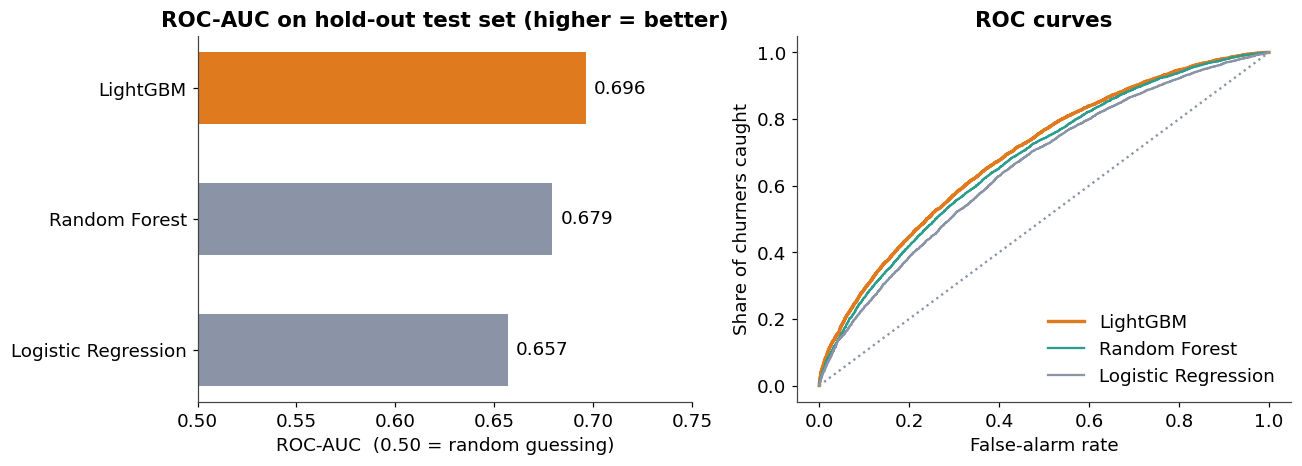

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
order = res.sort_values("Test ROC-AUC").index
bars = ax.barh(order, res.loc[order, "Test ROC-AUC"], color=[ORANGE if n == "LightGBM" else GREY for n in order], height=0.55)
for b, n in zip(bars, order):
    ax.text(b.get_width() + 0.004, b.get_y() + b.get_height() / 2, f"{res.loc[n, 'Test ROC-AUC']:.3f}", va="center", fontsize=12)
ax.set_xlim(0.5, 0.75); ax.set_title("ROC-AUC on hold-out test set (higher = better)"); ax.set_xlabel("ROC-AUC  (0.50 = random guessing)")
ax = axes[1]
for n, c in [("LightGBM", ORANGE), ("Random Forest", TEAL), ("Logistic Regression", GREY)]:
    fpr, tpr, _ = roc_curve(y_te, probas[n]); ax.plot(fpr, tpr, color=c, lw=2.2 if n == "LightGBM" else 1.5, label=n)
ax.plot([0, 1], [0, 1], ls=":", color=GREY); ax.legend(frameon=False, loc="lower right")
ax.set_title("ROC curves"); ax.set_xlabel("False-alarm rate"); ax.set_ylabel("Share of churners caught")
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png"); plt.show()

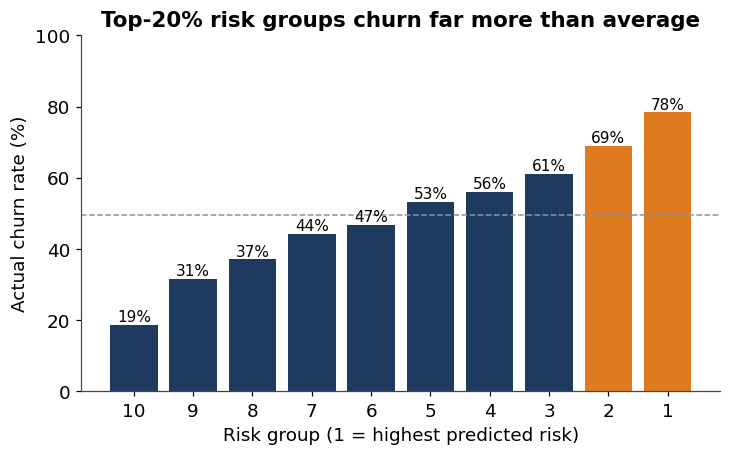

10    0.186
9     0.314
8     0.370
7     0.442
6     0.467
5     0.532
4     0.560
3     0.612
2     0.688
1     0.784
dtype: float64
Confusion @top20%:
 [[9032 1056]
 [6968 2944]]


In [16]:
best = models["LightGBM"]; p_best = probas["LightGBM"]
dec = pd.qcut(pd.Series(p_best).rank(method="first"), 10, labels=range(10, 0, -1))
dec_rate = pd.Series(y_te).groupby(dec, observed=True).mean().sort_index()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
cols = [ORANGE if i <= 2 else NAVY for i in dec_rate.index]
bars = ax.bar(dec_rate.index.astype(str), dec_rate.values * 100, color=cols)
for b, v in zip(bars, dec_rate.values):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=10)
ax.axhline(y_te.mean() * 100, ls="--", color=GREY, lw=1)
ax.set_xlabel("Risk group (1 = highest predicted risk)"); ax.set_ylabel("Actual churn rate (%)"); ax.set_ylim(0, 100)
ax.set_title("Top-20% risk groups churn far more than average")
plt.savefig(FIG / "risk_deciles.png"); plt.show()
print(dec_rate.round(3))
cm = confusion_matrix(y_te, p_best >= np.quantile(p_best, 1 - TOP)); print("Confusion @top20%:\n", cm)

## 6. Explainability – what drives the risk score? (SHAP)

change_mou               0.1872
eqpdays                  0.1699
months                   0.1369
usage_trend_3m           0.1327
crclscod                 0.0954
rev_per_minute           0.0895
uniqsubs                 0.0859
area                     0.0825
totmrc_Mean              0.0819
hnd_price                0.0816
lor                      0.0749
handset_age_vs_tenure    0.0622
drop_vce_Mean            0.0557
in_renewal_window        0.0556
mou_Mean                 0.0517
dtype: float64


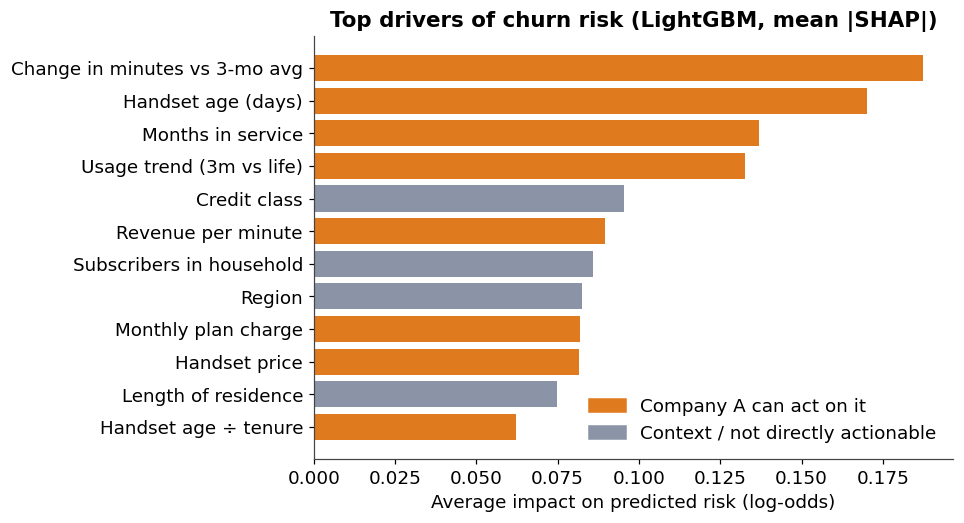

In [17]:
sample = X_te.sample(4000, random_state=SEED)
explainer = shap.TreeExplainer(best)
sv = explainer.shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
imp = pd.Series(np.abs(sv).mean(0), index=sample.columns).sort_values(ascending=False)
print(imp.head(15).round(4))

nice = {
    "eqpdays": "Handset age (days)", "months": "Months in service", "change_mou": "Change in minutes vs 3-mo avg",
    "handset_age_vs_tenure": "Handset age ÷ tenure", "hnd_price": "Handset price", "mou_Mean": "Monthly minutes",
    "totmrc_Mean": "Monthly plan charge", "in_renewal_window": "In renewal window (11–12m)", "hnd_webcap": "Handset web capability",
    "avgqty": "Avg calls / month", "rev_Mean": "Monthly revenue", "usage_trend_3m": "Usage trend (3m vs life)",
    "crclscod": "Credit class", "area": "Region", "asl_flag": "Spending limit", "uniqsubs": "Subscribers in household",
    "adjmou": "Lifetime minutes", "avg3mou": "Avg minutes (3m)", "ethnic": "Ethnicity code", "rev_per_minute": "Revenue per minute",
    "mou_cvce_Mean": "Completed-call minutes", "drop_block_rate": "Dropped/blocked call rate", "totrev": "Lifetime revenue",
    "prizm_social_one": "Social group", "avg6mou": "Avg minutes (6m)", "rev_trend_3m": "Revenue trend (3m vs life)",
    "actvsubs": "Active subs in household", "totcalls": "Lifetime calls", "adjrev": "Lifetime revenue (adj.)",
    "overage_share": "Overage share of bill", "care_per_100_calls": "Care calls per 100 calls", "avg3qty": "Avg calls (3m)",
    "avgmou": "Avg minutes (life)", "avgrev": "Avg revenue (life)", "dualband": "Dual-band handset", "refurb_new": "Refurbished handset",
    "models": "Handset models issued", "phones": "Handsets issued", "income": "Estimated income", "lor": "Length of residence",
}
top12 = imp.head(12)[::-1]
action = {"eqpdays", "handset_age_vs_tenure", "hnd_price", "hnd_webcap", "months", "in_renewal_window", "refurb_new",
          "totmrc_Mean", "change_mou", "usage_trend_3m", "overage_share", "rev_per_minute", "dualband", "phones", "models"}
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh([nice.get(i, i) for i in top12.index], top12.values, color=[ORANGE if i in action else GREY for i in top12.index])
ax.set_title("Top drivers of churn risk (LightGBM, mean |SHAP|)"); ax.set_xlabel("Average impact on predicted risk (log-odds)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label="Company A can act on it"), Patch(color=GREY, label="Context / not directly actionable")],
          frameon=False, loc="lower right")
plt.savefig(FIG / "shap_importance.png"); plt.show()

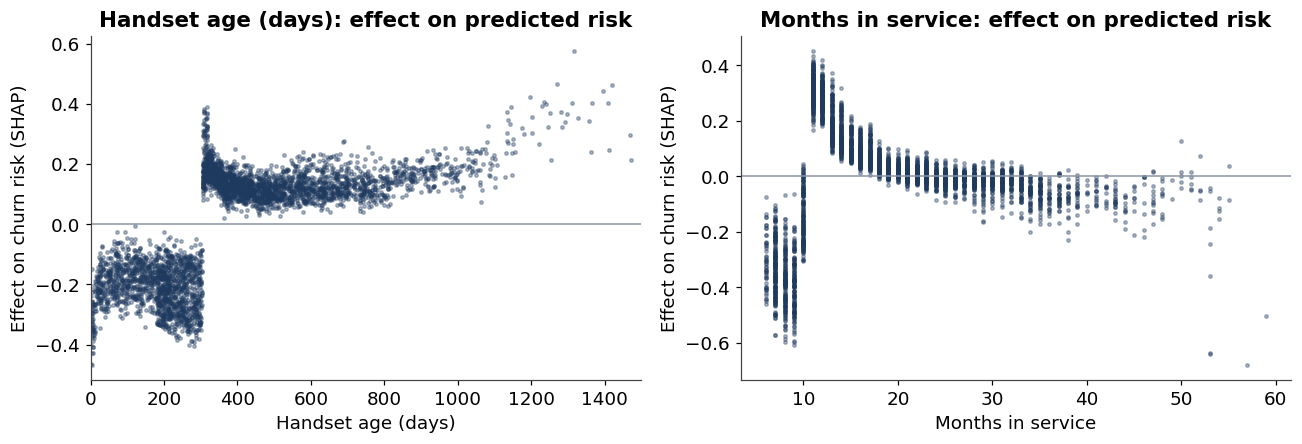

In [18]:
# Direction of effect for the key levers
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, f, lab in [(axes[0], "eqpdays", "Handset age (days)"), (axes[1], "months", "Months in service")]:
    i = list(sample.columns).index(f)
    ax.scatter(sample[f], sv[:, i], s=5, alpha=0.35, color=NAVY)
    ax.axhline(0, color=GREY, lw=1); ax.set_xlabel(lab); ax.set_ylabel("Effect on churn risk (SHAP)")
    ax.set_title(f"{lab}: effect on predicted risk")
axes[0].set_xlim(0, 1500)
plt.tight_layout(); plt.savefig(FIG / "shap_dependence.png"); plt.show()

## 7. From score to money – business impact simulation
Programme **"Renew & Upgrade"**: every month, score all customers; the riskiest 20% receive a proactive
renewal offer (discounted handset upgrade with a new 12-month commitment, or plan right-sizing if the handset is new).

Assumptions (stated on the slide; ranges tested in sensitivity):
* Cohort = the 100,000 customers in the PoC data; churners among flagged = model precision@20% on the test set.
* Value of a saved customer = their average monthly revenue × 12 months retained (new commitment).
* Cost per flagged customer = $5 outreach + 30% take-up × $100 handset subsidy = $35.
* Save rate = share of reached would-be churners who stay because of the offer: base case 20%.

In [19]:
N = len(df)
flagged = int(N * TOP)
prec = res.loc["LightGBM", "Precision@top20%"]
te = X_te.assign(p=p_best, churn=y_te)
flag_te = te[te.p >= np.quantile(p_best, 1 - TOP)]
arpu_flag_churn = flag_te.loc[flag_te.churn == 1, "rev_Mean"].median()   # median is robust to outliers
MONTHS_KEPT, OUTREACH, TAKEUP, SUBSIDY, SAVE = 12, 5, 0.30, 100, 0.20
cost_per = OUTREACH + TAKEUP * SUBSIDY
value_per_save = arpu_flag_churn * MONTHS_KEPT

def impact(save_rate, precision=prec):
    reached = flagged * precision
    saved = reached * save_rate
    gain = saved * value_per_save
    cost = flagged * cost_per
    return dict(reached=reached, saved=saved, gain=gain, cost=cost, net=gain - cost, roi=(gain - cost) / cost)

base = impact(SAVE)
rand = impact(SAVE, precision=y_te.mean())
breakeven = cost_per / (prec * value_per_save)
print(f"Flagged: {flagged:,} | precision {prec:.1%} | median ARPU of flagged churners ${arpu_flag_churn:.2f}")
print(f"Value per save ${value_per_save:,.0f} | cost per flagged ${cost_per:.0f}")
for k, v in base.items(): print(f"  {k:8s} {v:,.2f}")
print(f"Random targeting net: ${rand['net']:,.0f}  -> model adds ${base['net'] - rand['net']:,.0f}")
print(f"Break-even save rate: {breakeven:.1%}")
churn_before = df.churn.mean(); churn_after = (df.churn.sum() - base["saved"]) / N
print(f"Cohort churn {churn_before:.1%} -> {churn_after:.1%}")

Flagged: 20,000 | precision 73.6% | median ARPU of flagged churners $43.49
Value per save $522 | cost per flagged $35
  reached  14,720.00
  saved    2,944.00
  gain     1,536,326.40
  cost     700,000.00
  net      836,326.40
  roi      1.19
Random targeting net: $334,515  -> model adds $501,811
Break-even save rate: 9.1%
Cohort churn 49.6% -> 46.6%


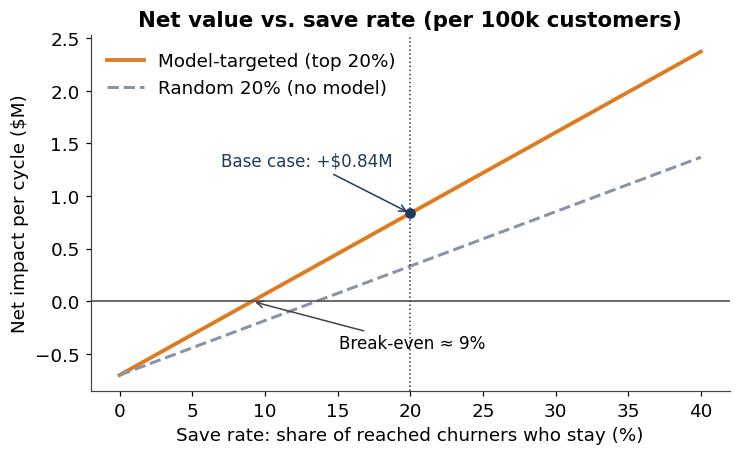

In [20]:
rates = np.linspace(0.0, 0.40, 41)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(rates * 100, [impact(r)["net"] / 1e6 for r in rates], color=ORANGE, lw=2.5, label="Model-targeted (top 20%)")
ax.plot(rates * 100, [impact(r, y_te.mean())["net"] / 1e6 for r in rates], color=GREY, lw=2, ls="--", label="Random 20% (no model)")
ax.axhline(0, color="#444", lw=1); ax.axvline(SAVE * 100, color=NAVY, ls=":", lw=1)
ax.scatter([SAVE * 100], [base["net"] / 1e6], color=NAVY, zorder=5)
ax.annotate(f"Base case: +${base['net']/1e6:.2f}M", (SAVE * 100, base["net"] / 1e6), xytext=(SAVE * 100 - 13, base["net"] / 1e6 + 0.45), arrowprops=dict(arrowstyle="->", color=NAVY),
            fontsize=11, color=NAVY)
ax.annotate(f"Break-even ≈ {breakeven:.0%}", (breakeven * 100, 0), xytext=(breakeven * 100 + 6, -0.45), fontsize=11,
            arrowprops=dict(arrowstyle="->", color="#444"))
ax.set_xlabel("Save rate: share of reached churners who stay (%)"); ax.set_ylabel("Net impact per cycle ($M)")
ax.set_title("Net value vs. save rate (per 100k customers)"); ax.legend(frameon=False, loc="upper left")
plt.savefig(FIG / "sensitivity.png"); plt.show()

In [21]:
# Which offer for whom? Split flagged customers by dominant actionable reason
# (use the hold-out test set only, so churn rates are not inflated by training-set fit)
flag_all = flag_te.copy()
seg = np.select(
    [flag_all.eqpdays >= 365, flag_all.months.between(11, 12)],
    ["Old handset (1y+) → upgrade offer", "Renewal window → loyalty renewal"],
    "Other → plan right-sizing / care call")
seg_t = flag_all.groupby(seg).agg(customers=("p", "size"), churn_rate=("churn", "mean"), median_rev=("rev_Mean", "median"))
seg_t["share"] = seg_t.customers / seg_t.customers.sum()
print(seg_t.round(3))
seg_t.round(4).to_csv(FIG / "segments.csv")
summary = {"flagged": flagged, "precision": prec, "arpu": arpu_flag_churn, "value_per_save": value_per_save,
           "cost_per": cost_per, **{f"base_{k}": v for k, v in base.items()}, "rand_net": rand["net"],
           "breakeven": breakeven, "churn_before": churn_before, "churn_after": churn_after}
pd.Series(summary).to_csv(FIG / "impact_summary.csv")

                                       customers  churn_rate  median_rev  \
Old handset (1y+) → upgrade offer           2187       0.724      40.249   
Other → plan right-sizing / care call        593       0.708      55.102   
Renewal window → loyalty renewal            1220       0.771      47.159   

                                       share  
Old handset (1y+) → upgrade offer      0.547  
Other → plan right-sizing / care call  0.148  
Renewal window → loyalty renewal       0.305  


## 8. Conclusions
* **Model:** LightGBM, ROC-AUC on the hold-out test set reported above (best of 3; CV results consistent → no overfitting).
* **Drivers:** handset age, tenure (renewal window), usage change and plan/handset price dominate – most are levers the
  company controls (upgrade timing, renewal offers, plan fit).
* **Proposal:** monthly risk scoring + targeted "Renew & Upgrade" offers to the top 20%; positive net value above the
  break-even save rate, and ~2x the value of untargeted offers.
* **Caveat:** the sample is balanced (~50% churn). In production, rescale counts to the real churn rate and validate with an A/B pilot.